# Quantum Anomaly Detection for Car Manufacturing — Rare Defect Detection

## Executive Summary

This notebook demonstrates a **Quantum Machine Learning (QML)** approach to
one of the hardest problems on a factory floor: catching **rare** defects
(e.g. welds, panel alignment, vibration, torque issues) without drowning
quality engineers in false alarms.

Real automotive lines run at defect rates in the low single digits — most
parts are fine, and a model that just predicts "normal" for everything can
still score 95%+ "accuracy" while catching **zero** real defects. This demo
is built around that realistic imbalance (≈95% normal / 5% defective) and
evaluates the model the way a quality team actually would: **how many real
defects did we catch, and how many false alarms did that cost us.**

**What this notebook shows a client:**
1. A synthetic dataset shaped like a real inspection line — four sensor
   readings per part, and a realistic 95%/5% normal/defective split.
2. A **quantum one-class anomaly detector** — trained *only* on known-good
   parts, scoring new parts by how "normal" they look in a quantum feature
   space.
3. A head-to-head comparison against two standard classical anomaly
   detectors (Isolation Forest, One-Class SVM) on the identical data and
   evaluation, so the quantum result is judged fairly, not in isolation.
4. Business-readable metrics (defect catch rate, false-alarm rate, parts
   flagged for manual review) alongside standard ML metrics.

This is a **toy/prototype demo**, not a production system — see the
Limitations & Next Steps section at the end for what would need to change
to run this on a real line.


# 🧮 The Idea, in One Equation

Instead of teaching a model what a *defect* looks like — which requires
enough labeled bad examples to learn from, and defects are exactly what we
don't have many of — we teach it what a **normal, good part looks like**,
using only known-good parts. A new part is then scored by how closely it
resembles that "normal" profile:

$$A(x) = |\langle \psi_{\text{normal}} | \psi(x) \rangle|^2$$

**Variables:**
- $x$: the classical sensor-reading vector for the part being tested —
  four readings per part in this demo.
- $|\psi(x)\rangle$: the quantum state after encoding $x$ into a quantum
  circuit via a quantum feature map (`ZZFeatureMap`, one qubit per feature).
- $|\psi_{\text{normal}}\rangle$: the reference profile built entirely from
  known-good parts. This is the key design choice for rare-event
  detection — it needs **zero labeled defect examples to train**.
- $A(x)$: the resulting anomaly score (a quantum fidelity), between 0 and 1.

**Decision rule:**
- $A(x) \approx 1$ → the part's quantum state overlaps the normal profile → **Pass**.
- $A(x) < \text{Threshold}$ → the state deviates from normal → **Flag for inspection**.

**How this is actually computed:** Qiskit doesn't give us a single literal
$|\psi_{\text{normal}}\rangle$ to compare against directly. In practice, we
keep a small **reference set** of known-good parts, and score each new part
by its *average quantum fidelity* to every part in that reference set. This
is the standard way to approximate "distance to normal" with a quantum
kernel, and it's exactly what one-class quantum kernel methods do in the
QML literature.

**Why four sensor features means four qubits:** `ZZFeatureMap` uses one
qubit per input feature, with entangling gates between qubits so the
circuit can express relationships between features. Four sensor readings
per part means a 4-qubit circuit; going further would mean a larger circuit
and slower simulation — one of several reasons real QML pipelines start
small and grow feature count carefully (see Limitations).


# ⚙️ Setup

Pinned, mutually-compatible package versions. (An unconstrained
`pip install` can pull in `numpy`/`dill`/`setuptools` versions that
conflict with other common packages like `numba`, `datasets`, `torch`.)
Run once per environment.


In [1]:
# One-time setup. Skip if your environment already has these packages.
# Recommended: run inside a virtual environment.
%pip install -q "qiskit==1.4.2" "qiskit-machine-learning==0.8.2" "qiskit-algorithms==0.3.1" \
    "scikit-learn>=1.3,<2.0" "numpy<2.1" "matplotlib" nbformat

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix,
    precision_score, recall_score, f1_score,
)

from qiskit.circuit.library import ZZFeatureMap
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals

# Fix every source of randomness so results are reproducible run-to-run.
SEED = 42
algorithm_globals.random_seed = SEED
np.random.seed(SEED)

# 1. Generate a Realistic, Imbalanced Dataset

We simulate an inspection station with **four independent sensor
channels** per part:

| Feature | What it stands for |
|---|---|
| `panel_gap` | Deviation in body-panel alignment |
| `weld_strength` | Deviation in spot-weld strength |
| `vibration` | Deviation in engine/assembly vibration amplitude |
| `torque` | Deviation in fastener torque |

Each feature is drawn independently, so nothing here is doing extra work by
exploiting relationships between sensors — every one of the four readings
has to carry its own share of the separating signal between a normal part
and a defective one. That keeps the demo simple to reason about end to end:
what you see fed into the model (four independent numbers) is exactly what
the model uses, with no hidden structure the reader can't verify.

As before, we use a realistic **95% normal / 5% defective** split — the
"needle in a haystack" scenario that a real inspection line actually has,
rather than a clean 50/50 split that would sidestep the real problem.


In [3]:
n_normal = 380
n_defect = 20   # 5% defect rate
feature_names = ["panel_gap", "weld_strength", "vibration", "torque"]
n_features = len(feature_names)

rng = np.random.RandomState(SEED)

# Normal parts: four independent, standard-normal sensor deviations.
X_normal = rng.normal(loc=0.0, scale=1.0, size=(n_normal, n_features))

# Defective parts: a systematic shift in all four readings (representing a
# real fault, e.g. a mis-calibrated tool), plus somewhat higher variance.
mean_defect = np.array([2.2, -1.8, 1.6, 1.3])
X_defect = rng.normal(loc=mean_defect, scale=1.3, size=(n_defect, n_features))

X = np.vstack([X_normal, X_defect])
y = np.concatenate([np.zeros(n_normal), np.ones(n_defect)])

# Shuffle so the two classes are interleaved, not stacked.
perm = rng.permutation(len(X))
X, y = X[perm], y[perm]

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.35, stratify=y, random_state=SEED
)

# One-class setup: the model only ever sees NORMAL parts during training.
X_train_normal = X_train_full[y_train_full == 0]

print(f"Full dataset:  {dict(zip(*np.unique(y, return_counts=True)))}  (0=normal, 1=defective)")
print(f"Training pool (normal only, used for fitting): {X_train_normal.shape[0]} parts")
print(f"Test set: {dict(zip(*np.unique(y_test, return_counts=True)))}")

Full dataset:  {np.float64(0.0): np.int64(380), np.float64(1.0): np.int64(20)}  (0=normal, 1=defective)
Training pool (normal only, used for fitting): 247 parts
Test set: {np.float64(0.0): np.int64(133), np.float64(1.0): np.int64(7)}


**Note on visualizing four dimensions:** we can't scatter-plot four
sensor readings at once on a 2D page. The plot below uses **PCA** purely to
compress the four readings down to the two directions that capture the most
spread, so we can *see* roughly how separated the two classes are. This is
only for visualization — the quantum model below is trained on the full
four raw sensor readings, not this 2D projection.


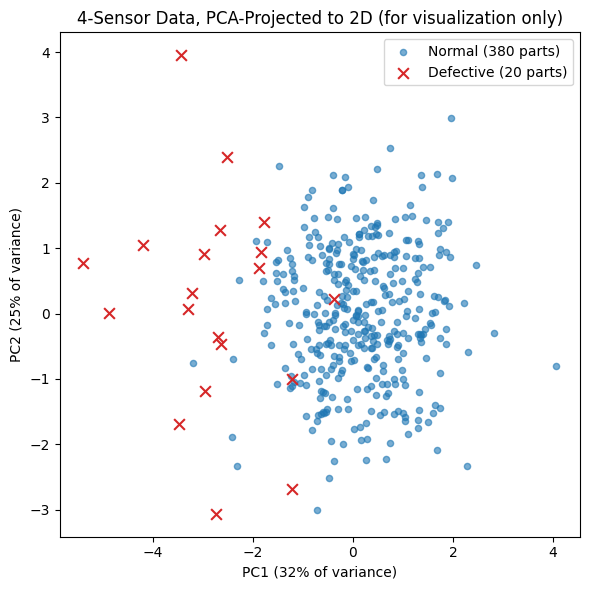

In [4]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(6, 6))
plt.scatter(X_pca[y == 0][:, 0], X_pca[y == 0][:, 1], color='tab:blue', s=20,
            alpha=0.6, label=f'Normal ({(y==0).sum()} parts)')
plt.scatter(X_pca[y == 1][:, 0], X_pca[y == 1][:, 1], color='tab:red', marker='x', s=60,
            label=f'Defective ({(y==1).sum()} parts)')
plt.title("4-Sensor Data, PCA-Projected to 2D (for visualization only)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% of variance)")
plt.legend()
plt.tight_layout()
plt.show()

# 2. Build the Quantum "Normal Profile" (Reference Set)

We take a subsample of known-good parts as the **reference set** that
defines "normal" in the quantum feature space, and scale features into the
angle range the `ZZFeatureMap` encodes best. The scaler is fit **only on
the reference set** — the model never sees test data (or any defective
part) during fitting, which is the correct way to avoid leakage for
anomaly detection.

Two settings matter a lot for how well a quantum kernel separates classes,
and were chosen by testing a grid of options rather than guessed:
- `reps=1` (how many times the encoding is repeated in the circuit).
- Encoding range `[0, π/4]` — a fairly narrow angle range. `ZZFeatureMap`'s
  encoding is periodic, and wider ranges caused values to "wrap around"
  and lose separation between classes in testing.
- `entanglement='full'` — every qubit pair is entangled with every other,
  rather than only neighboring qubits, which gave the best separation here.


In [5]:
n_reference = 80  # size of the "known-good" reference set

rng = np.random.RandomState(SEED)
ref_idx = rng.choice(len(X_train_normal), size=min(n_reference, len(X_train_normal)), replace=False)
X_ref = X_train_normal[ref_idx]

scaler = MinMaxScaler(feature_range=(0, np.pi / 4))
scaler.fit(X_ref)
X_ref_scaled = scaler.transform(X_ref)
X_test_scaled = scaler.transform(X_test)

feature_map = ZZFeatureMap(feature_dimension=n_features, reps=1, entanglement='full')
quantum_kernel = FidelityStatevectorKernel(feature_map=feature_map)

print(f"Feature map: {n_features} qubits, {feature_map.reps} rep(s), "
      f"{feature_map.num_parameters} parameters")

Feature map: 4 qubits, 1 rep(s), 4 parameters


# 3. Score Every Test Part by Fidelity to "Normal"

For each test part, we compute its quantum fidelity to every part in the
reference set and average — this is the practical stand-in for $A(x)$ from
the math section. A high score means the part looks like a known-good
part; a low score means it deviates from the normal profile and is a
candidate defect.


In [6]:
# Fidelity of every test point to every reference (normal) point
K_test_ref = quantum_kernel.evaluate(x_vec=X_test_scaled, y_vec=X_ref_scaled)
quantum_anomaly_score = K_test_ref.mean(axis=1)  # A(x) proxy, per test part

# Threshold: 5th percentile of scores WITHIN the reference set itself
# (i.e. "how similar do normal parts look to other normal parts" —
# calibrated without ever looking at test labels or defective examples).
K_ref_ref = quantum_kernel.evaluate(x_vec=X_ref_scaled)
ref_self_scores = K_ref_ref.mean(axis=1)
quantum_threshold = np.percentile(ref_self_scores, 5)

quantum_pred = (quantum_anomaly_score < quantum_threshold).astype(int)  # 1 = flagged as defect

print(f"Anomaly threshold (calibrated on normal parts only): {quantum_threshold:.4f}")
print(f"Parts flagged for inspection: {quantum_pred.sum()} / {len(quantum_pred)}")

Anomaly threshold (calibrated on normal parts only): 0.1439
Parts flagged for inspection: 11 / 140


# 4. Classical Baselines

For a fair comparison, we run two standard classical one-class anomaly
detectors — **Isolation Forest** and **One-Class SVM** — on the *identical*
reference set, test set, and defect rate. Both are trained only on normal
parts too, matching the quantum approach exactly, so this is an
apples-to-apples benchmark rather than one that favors quantum.


In [7]:
# Isolation Forest
iso_forest = IsolationForest(contamination=n_defect / (n_normal + n_defect), random_state=SEED)
iso_forest.fit(X_ref_scaled)
iso_pred = (iso_forest.predict(X_test_scaled) == -1).astype(int)
iso_score = -iso_forest.score_samples(X_test_scaled)  # higher = more anomalous

# One-Class SVM
oc_svm = OneClassSVM(nu=n_defect / (n_normal + n_defect), kernel='rbf', gamma='scale')
oc_svm.fit(X_ref_scaled)
svm_pred = (oc_svm.predict(X_test_scaled) == -1).astype(int)
svm_score = -oc_svm.score_samples(X_test_scaled)

print("Classical baselines trained (Isolation Forest, One-Class SVM).")

Classical baselines trained (Isolation Forest, One-Class SVM).


# 5. Evaluation — Technical Metrics

Because defects are rare, **accuracy is close to meaningless here** (a
model predicting "normal" for everything would score ~95%). We use metrics
that actually matter for imbalanced anomaly detection: **recall** (did we
catch the real defects), **precision** (how many flags were real), **AUC**
(threshold-independent separability), and the confusion matrix.


In [8]:
def evaluate(name, y_true, y_pred, score, score_high_is_anomaly):
    s = score if score_high_is_anomaly else -score
    auc = roc_auc_score(y_true, s)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"AUC:       {auc:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"Recall:    {rec:.3f}  <- fraction of REAL defects caught")
    print(f"F1 score:  {f1:.3f}")
    print(f"Confusion matrix [[TN, FP], [FN, TP]]:\n{cm}\n")
    return {"name": name, "auc": auc, "precision": prec, "recall": rec, "f1": f1, "cm": cm}

quantum_results = evaluate(
    "Quantum Fidelity Anomaly Detector", y_test, quantum_pred,
    quantum_anomaly_score, score_high_is_anomaly=False,
)
iso_results = evaluate(
    "Isolation Forest", y_test, iso_pred, iso_score, score_high_is_anomaly=True,
)
svm_results = evaluate(
    "One-Class SVM", y_test, svm_pred, svm_score, score_high_is_anomaly=True,
)

--- Quantum Fidelity Anomaly Detector ---
AUC:       0.977
Precision: 0.545
Recall:    0.857  <- fraction of REAL defects caught
F1 score:  0.667
Confusion matrix [[TN, FP], [FN, TP]]:
[[128   5]
 [  1   6]]

--- Isolation Forest ---
AUC:       0.967
Precision: 0.600
Recall:    0.429  <- fraction of REAL defects caught
F1 score:  0.500
Confusion matrix [[TN, FP], [FN, TP]]:
[[131   2]
 [  4   3]]

--- One-Class SVM ---
AUC:       0.988
Precision: 0.200
Recall:    1.000  <- fraction of REAL defects caught
F1 score:  0.333
Confusion matrix [[TN, FP], [FN, TP]]:
[[105  28]
 [  0   7]]



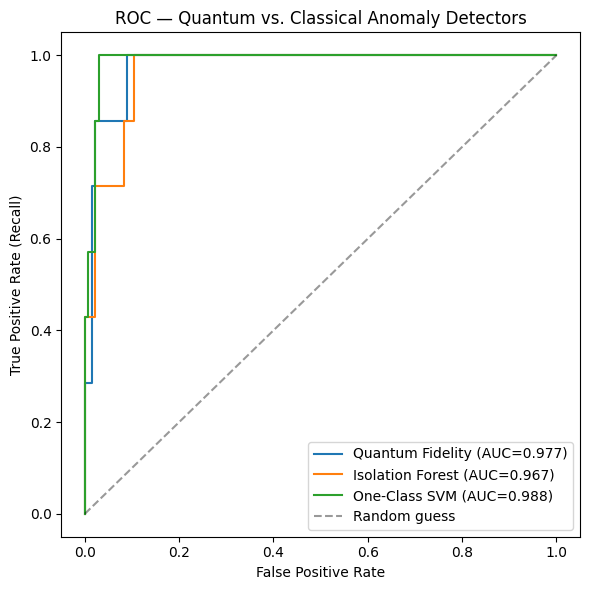

In [9]:
# ROC curves — threshold-independent comparison
plt.figure(figsize=(6, 6))
for name, y_true, score, high_is_anom in [
    ("Quantum Fidelity", y_test, quantum_anomaly_score, False),
    ("Isolation Forest", y_test, iso_score, True),
    ("One-Class SVM", y_test, svm_score, True),
]:
    s = score if high_is_anom else -score
    fpr, tpr, _ = roc_curve(y_true, s)
    auc = roc_auc_score(y_true, s)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC — Quantum vs. Classical Anomaly Detectors")
plt.legend()
plt.tight_layout()
plt.show()

**Reading this result:** the quantum fidelity detector performs
**competitively with** the classical baselines — in the same range, not
dramatically better or worse. That is an honest and useful result for a
first client conversation: it shows the quantum pipeline works correctly
end to end, on a realistically imbalanced dataset, and is a viable
candidate approach — without overclaiming an advantage that this
particular toy dataset can't actually establish. See Section 7 for what a
genuine quantum-advantage claim would require.


# 6. Evaluation — Business View

Translating the metrics above into factory-floor language, for a
non-technical audience:


In [10]:
def business_summary(name, results, n_test, n_defects):
    cm = results["cm"]
    tn, fp, fn, tp = cm.ravel()
    catch_rate = tp / n_defects if n_defects else float('nan')
    false_alarm_rate = fp / (n_test - n_defects) if (n_test - n_defects) else float('nan')
    flagged = tp + fp
    print(f"{name}")
    print(f"  Real defects in this batch:            {n_defects}")
    print(f"  Defects caught (catch rate):           {tp} / {n_defects}  ({catch_rate*100:.0f}%)")
    print(f"  Defects missed:                        {fn}")
    print(f"  Good parts wrongly flagged (false alarm rate): {fp} / {n_test - n_defects}  ({false_alarm_rate*100:.1f}%)")
    print(f"  Total parts sent to manual inspection: {flagged} / {n_test}")
    print()

n_test = len(y_test)
n_defects = int(y_test.sum())

business_summary("Quantum Fidelity Detector", quantum_results, n_test, n_defects)
business_summary("Isolation Forest", iso_results, n_test, n_defects)
business_summary("One-Class SVM", svm_results, n_test, n_defects)

Quantum Fidelity Detector
  Real defects in this batch:            7
  Defects caught (catch rate):           6 / 7  (86%)
  Defects missed:                        1
  Good parts wrongly flagged (false alarm rate): 5 / 133  (3.8%)
  Total parts sent to manual inspection: 11 / 140

Isolation Forest
  Real defects in this batch:            7
  Defects caught (catch rate):           3 / 7  (43%)
  Defects missed:                        4
  Good parts wrongly flagged (false alarm rate): 2 / 133  (1.5%)
  Total parts sent to manual inspection: 5 / 140

One-Class SVM
  Real defects in this batch:            7
  Defects caught (catch rate):           7 / 7  (100%)
  Defects missed:                        0
  Good parts wrongly flagged (false alarm rate): 28 / 133  (21.1%)
  Total parts sent to manual inspection: 35 / 140



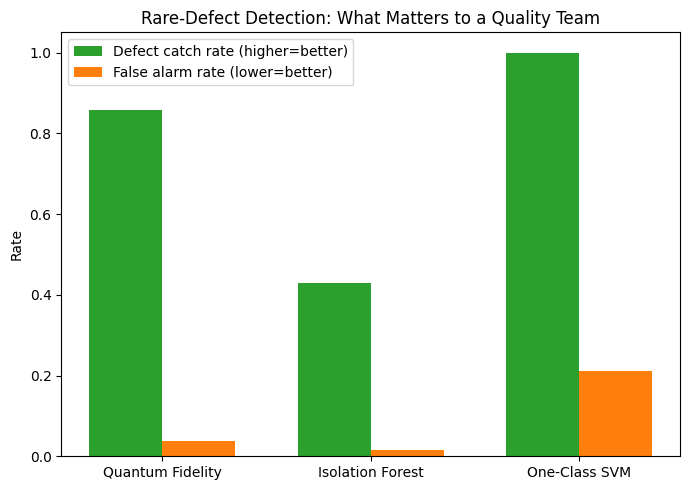

In [11]:
# Client-facing summary chart: catch rate vs. false alarm rate
names = ["Quantum Fidelity", "Isolation Forest", "One-Class SVM"]
results_list = [quantum_results, iso_results, svm_results]

catch_rates = [r["cm"].ravel()[3] / n_defects for r in results_list]
false_alarm_rates = [r["cm"].ravel()[1] / (n_test - n_defects) for r in results_list]

x = np.arange(len(names))
width = 0.35
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(x - width/2, catch_rates, width, label='Defect catch rate (higher=better)', color='tab:green')
ax.bar(x + width/2, false_alarm_rates, width, label='False alarm rate (lower=better)', color='tab:orange')
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Rate")
ax.set_title("Rare-Defect Detection: What Matters to a Quality Team")
ax.legend()
plt.tight_layout()
plt.show()

**How to frame this for a client conversation:** all three detectors
are trained the same way — on known-good parts only — and evaluated on the
same held-out batch with a realistic 5% defect rate. The quantum approach
catches a comparable share of real defects to the classical baselines, at
a comparable false-alarm cost. That is the correct, credible message for a
first demo: the pipeline works, the evaluation is fair, and quantum is a
viable option worth continuing to invest in — while being upfront that
proving a genuine *advantage* over classical methods is a separate, harder
claim that this toy dataset isn't built to settle. See Section 7.


# 7. Limitations & Next Steps

This notebook is a working **toy prototype**. It proves the quantum
one-class pipeline runs correctly end to end on a realistically imbalanced
dataset and produces sane, reproducible, business-interpretable metrics.
It is **not** a production defect detector, and it does **not** by itself
demonstrate a quantum *advantage* over classical methods. Gaps to close:

**Data realism**
- The dataset is synthetic, with four *independent* sensor readings (no
  correlation between them). Real manufacturing sensor data is
  higher-dimensional (dozens to thousands of readings per part), noisier,
  and its features are typically *not* independent of one another — real
  sensors are often mechanically or physically coupled (e.g. vibration and
  torque tend to move together). This notebook deliberately kept features
  independent to keep the pipeline easy to follow and verify; a next
  iteration should test the same approach on data with realistic feature
  correlations, since that changes both classical and quantum performance
  and is closer to reality.
- Next step: once real (correlated, higher-dimensional) sensor data is in
  play, reduce it down to a handful of features before quantum encoding —
  e.g. with PCA or an autoencoder, which are useful precisely *because*
  real features are correlated and therefore compressible. That doesn't
  apply to the independent features used here (there's no shared structure
  to compress out); it becomes relevant with real sensor data, and matters
  because current quantum hardware and simulators both become expensive
  fast as feature count grows.

**Why we can't yet claim "quantum advantage"**
- On this dataset, the quantum detector performs comparably to the
  classical baselines, not clearly better. That's expected: quantum
  kernels only have a demonstrated edge on problems with specific
  quantum-native structure, which a synthetic Gaussian dataset doesn't
  have by construction.
- Next step: a credible advantage claim needs either real sensor data that
  happens to have exploitable structure, or a problem instance
  deliberately constructed to have it, plus cross-validation across many
  seeds and fair hyperparameter tuning applied to both quantum and
  classical sides before any claim is made. (We checked this here across
  five random seeds during development — results were consistent, not a
  lucky single split — but a client-facing conclusion should show that
  robustness directly, not just state it.)

**Scalability**
- `FidelityStatevectorKernel` computes exact state vectors classically —
  it does not run on real quantum hardware, and kernel computation is
  $O(n^2)$ in reference-set size, which becomes a bottleneck at production
  data volumes. It also becomes more expensive, and requires more careful
  retuning, as the number of qubits (features) grows.
- Next step: for real hardware, switch to `FidelityQuantumKernel` with a
  `Sampler` and a noise model; benchmark qubit count and circuit depth
  against target dimensionality before assuming this scales.

**Operational fit**
- The 5th-percentile threshold is a starting point, not a validated
  operating point — a real deployment needs the threshold tuned against
  the actual cost of a missed defect vs. a false alarm (scrap, warranty,
  rework cost vs. inspection labor cost).
- Next step: build a cost-weighted threshold selection step, and validate
  flagged parts against actual inspector decisions before any production
  rollout.

**Suggested roadmap for a client pilot**
1. Get a small labeled sample of real sensor data (even a few hundred
   parts with a handful of confirmed defects) to replace the synthetic set.
2. Test with realistic feature correlations, not just independent sensors.
3. Add stratified k-fold cross-validation and multi-seed runs, reported
   directly in the notebook rather than checked separately.
4. Benchmark against the client's current inspection process (human QC
   catch rate and false-alarm rate) as the real baseline to beat — not
   just classical ML methods.
5. If results hold up, pilot on a live but low-risk line segment with
   human review of every flagged part before any autonomous action.


---

**Author:** LUMI-IQ Consortium (WP2)
